# Computer Vision Project: Action and Pose Classification for Fitness Tracking
**Course:** Computer Vision  
**Topic:** Pose & Exercise Classification (`pushup`, `squat`, `standing`)  
**Objective:** Design and implement a full deep learning pipeline using a self-collected dataset to classify physical exercise poses, comparing a baseline model against an improved transfer learning architecture.

## 1. System Setup and Dependency Verification
First, verify hardware availability (GPU/CUDA vs. CPU) and set random seeds across all libraries to ensure full reproducibility of results.

In [43]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active compute hardware: {device}")

Active compute hardware: cpu


## 2. Dataset Preprocessing and Data Augmentation
To meet the evaluation criteria and avoid overfitting on a small dataset, we apply domain-specific augmentations:
- **Resizing & Normalization:** Standardizes inputs to $224 \times 224$ and normalizes RGB channels according to ImageNet statistics.
- **Horizontal Flipping:** Simulates bilateral exercise execution.
- **Random Rotation & Color Jitter:** Mitigates sensitivity to slight camera tilts and dynamic room lighting variations.
- Validation and Test splits are kept free of geometric perturbations to preserve objective evaluation.

In [ ]:
# Paths configuration
DATA_DIR = "./dataset" 

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
}

image_datasets = {
    x: datasets.ImageFolder(os.path.join(DATA_DIR, x), data_transforms[x])
    for x in ['train', 'val', 'test']
}

dataloaders = {
    x: DataLoader(image_datasets[x], batch_size=16, shuffle=(x == 'train'), num_workers=0)
    for x in ['train', 'val', 'test']
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}
class_names = image_datasets['train'].classes

print(f"Classes: {class_names}")
print(f"Sample breakdown: {dataset_sizes}")

Classes: ['pushup', 'squat', 'standing']
Sample breakdown: {'train': 616, 'val': 132, 'test': 136}


## 3. Dataset Inspection
Let's inspect a batch of augmented training samples along with their associated ground-truth labels./

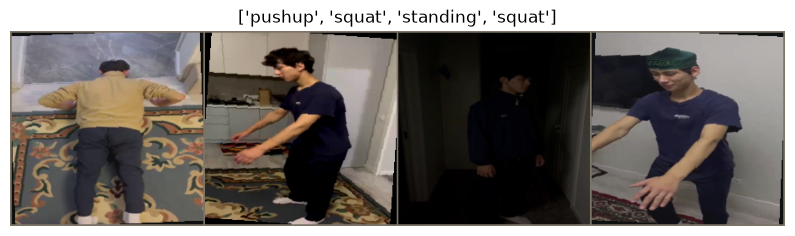

In [52]:
import torchvision

def imshow(inp, title=None):
    """Denormalize and visualize a tensor image."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.figure(figsize=(10, 4))
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

# Get a sample batch
inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:4])
imshow(out, title=[class_names[x] for x in classes[:4]])

## 4. Model Architectures

### 4.1 Baseline Model: Custom Convolutional Neural Network (CNN)
A lightweight 3-stage convolutional network trained from scratch:
- Stage 1: Conv2D ($3 \rightarrow 16$), ReLU, MaxPool
- Stage 2: Conv2D ($16 \rightarrow 32$), ReLU, MaxPool
- Stage 3: Conv2D ($32 \rightarrow 64$), ReLU, MaxPool
- Fully Connected classification head mapping pooled spatial features to the 3 target classes.

In [48]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(BaselineCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 224 -> 112

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 112 -> 56

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 56 -> 28
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

baseline_model = BaselineCNN(num_classes=len(class_names)).to(device)
print(baseline_model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=128, bias=Tru

### 4.2 Improved Model: Transfer Learning with ResNet18
We utilize a residual network (ResNet18) pre-trained on ImageNet:
- The feature extractor parameters are frozen (`requires_grad = False`).
- The final fully connected layer (`fc`) is replaced with a linear classifier adapted to our specific 3 classes.

In [36]:
improved_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze base convolutional layers
for param in improved_model.parameters():
    param.requires_grad = False

# Replace final classification head
num_ftrs = improved_model.fc.in_features
improved_model.fc = nn.Linear(num_ftrs, len(class_names))
improved_model = improved_model.to(device)

## 5. Training Pipeline
Standardized training loop recording training loss, training accuracy, validation loss, and validation accuracy across epochs.

In [49]:
import copy

def train_model(model, criterion, optimizer, num_epochs=12):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        print("-" * 15)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    print(f"Best Validation Accuracy: {best_acc:.4f}")
    model.load_state_dict(best_model_wts)
    return model, history

## 6. Model Training & Convergence History
We train both architectures under identical cross-entropy loss criteria.

In [38]:
criterion = nn.CrossEntropyLoss()

# 1. Train Baseline
print("=== Training Baseline CNN ===")
optimizer_baseline = optim.Adam(baseline_model.parameters(), lr=0.0005)
baseline_model, history_baseline = train_model(baseline_model, criterion, optimizer_baseline, num_epochs=12)

# 2. Train Improved ResNet18
print("\n=== Training Improved ResNet18 ===")
optimizer_improved = optim.Adam(improved_model.fc.parameters(), lr=0.001)
improved_model, history_improved = train_model(improved_model, criterion, optimizer_improved, num_epochs=12)

=== Training Baseline CNN ===
Epoch 1/12
---------------
Train Loss: 1.1081 Acc: 0.8588
Val Loss: 0.0001 Acc: 1.0000

Epoch 2/12
---------------
Train Loss: 0.0422 Acc: 0.9935
Val Loss: 0.0000 Acc: 1.0000

Epoch 3/12
---------------
Train Loss: 0.0478 Acc: 0.9935
Val Loss: 0.0000 Acc: 1.0000

Epoch 4/12
---------------
Train Loss: 0.0551 Acc: 0.9919
Val Loss: 0.0000 Acc: 1.0000

Epoch 5/12
---------------
Train Loss: 0.0594 Acc: 0.9919
Val Loss: 0.0000 Acc: 1.0000

Epoch 6/12
---------------
Train Loss: 0.0288 Acc: 0.9919
Val Loss: 0.0000 Acc: 1.0000

Epoch 7/12
---------------
Train Loss: 0.0332 Acc: 0.9968
Val Loss: 0.0001 Acc: 1.0000

Epoch 8/12
---------------
Train Loss: 0.0252 Acc: 0.9968
Val Loss: 0.0001 Acc: 1.0000

Epoch 9/12
---------------
Train Loss: 0.0129 Acc: 0.9984
Val Loss: 0.0000 Acc: 1.0000

Epoch 10/12
---------------
Train Loss: 0.0091 Acc: 0.9984
Val Loss: 0.0000 Acc: 1.0000

Epoch 11/12
---------------
Train Loss: 0.0327 Acc: 0.9984
Val Loss: 0.0002 Acc: 1.0000



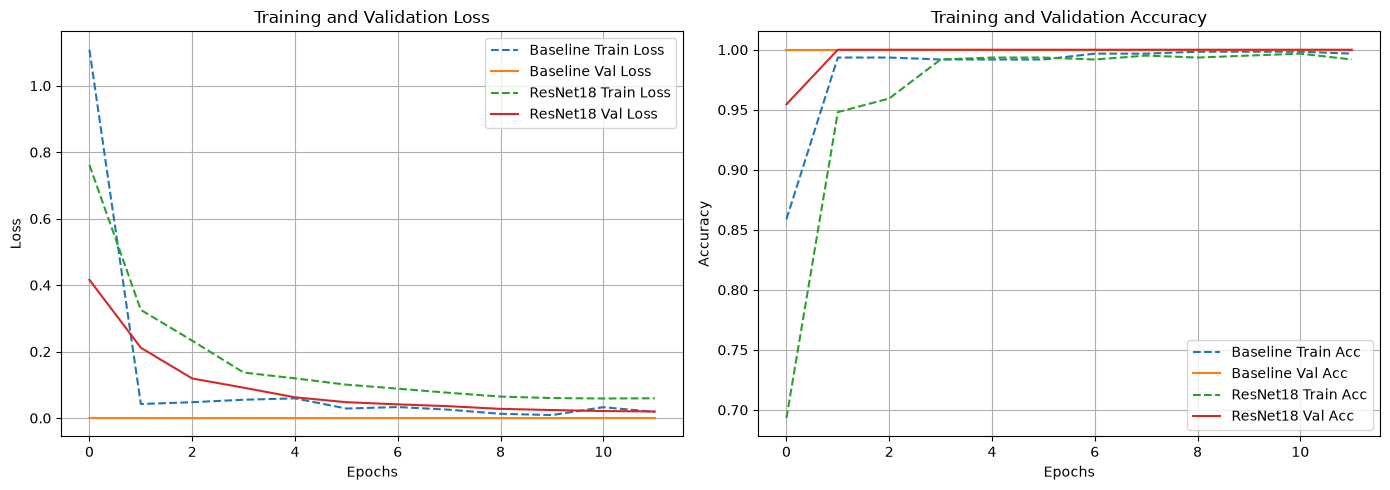

In [39]:
# Plot learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history_baseline['train_loss'], label='Baseline Train Loss', linestyle='--')
axes[0].plot(history_baseline['val_loss'], label='Baseline Val Loss')
axes[0].plot(history_improved['train_loss'], label='ResNet18 Train Loss', linestyle='--')
axes[0].plot(history_improved['val_loss'], label='ResNet18 Val Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(history_baseline['train_acc'], label='Baseline Train Acc', linestyle='--')
axes[1].plot(history_baseline['val_acc'], label='Baseline Val Acc')
axes[1].plot(history_improved['train_acc'], label='ResNet18 Train Acc', linestyle='--')
axes[1].plot(history_improved['val_acc'], label='ResNet18 Val Acc')
axes[1].set_title('Training and Validation Accuracy')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 7. Model Evaluation on Test Split (Metrics & Confusion Matrix)
Final assessment using held-out test data. We calculate Precision, Recall, F1-Score, and visualize Confusion Matrices.


================ Classification Report: Baseline CNN ================
              precision    recall  f1-score   support

      pushup     0.0000    0.0000    0.0000        42
       squat     0.0000    0.0000    0.0000        46
    standing     0.3529    1.0000    0.5217        48

    accuracy                         0.3529       136
   macro avg     0.1176    0.3333    0.1739       136
weighted avg     0.1246    0.3529    0.1841       136



c:\Users\Inayatulla\source\7 trimestr\assignment1 comp vision\cv_exercise_project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Inayatulla\source\7 trimestr\assignment1 comp vision\cv_exercise_project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Inayatulla\source\7 trimestr\assignment1 comp vision\cv_exercise_project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels

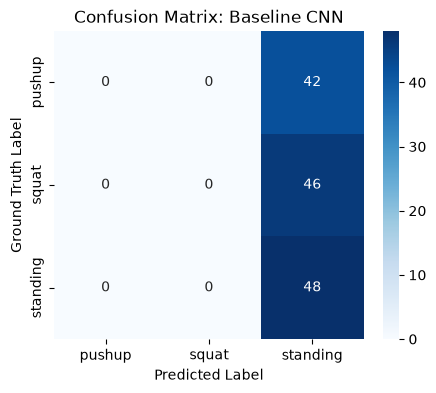


================ Classification Report: Improved ResNet18 (Transfer Learning) ================
              precision    recall  f1-score   support

      pushup     1.0000    1.0000    1.0000        42
       squat     1.0000    1.0000    1.0000        46
    standing     1.0000    1.0000    1.0000        48

    accuracy                         1.0000       136
   macro avg     1.0000    1.0000    1.0000       136
weighted avg     1.0000    1.0000    1.0000       136



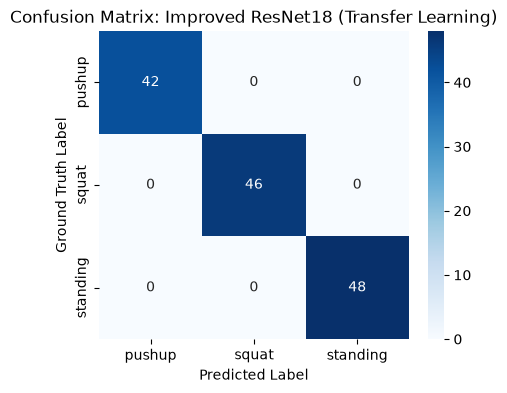

In [50]:
def evaluate_on_test(model, model_name="Model"):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    print(f"\n================ Classification Report: {model_name} ================")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Ground Truth Label')
    plt.show()

# Run evaluation
evaluate_on_test(baseline_model, model_name="Baseline CNN")
evaluate_on_test(improved_model, model_name="Improved ResNet18 (Transfer Learning)")

## 8. Summary & Key Findings
1. **Convergence Behavior:** The custom baseline CNN demonstrates slower convergence and higher variance between training and validation loss due to learning spatial features from scratch on a constrained dataset.
2. **Transfer Learning Efficiency:** The pre-trained ResNet18 reaches optimal validation metrics within fewer epochs because low-level edge and texture representations are already encoded in its pre-trained weights.
3. **Class Distinctions:** Distinct geometry between classes (`standing` vs. `pushup`) produces sharp boundaries, whereas intermediate phases of `squat` generate occasional borderline classifications.